# SpaceX Capstone — Visual Evidence Generator

In [1]:
# 2. Imports e pasta de saída
from pathlib import Path
import json, re, warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster
import plotly.express as px

warnings.filterwarnings("ignore")
OUT = Path("spacex_evidence")
OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Arquivos serão salvos em:", OUT.resolve())

Arquivos serão salvos em: C:\Users\Marcos\Desktop\spacex_evidence


In [2]:
# 3. Baixar dataset de lançamentos usado no laboratório Dash
DATA_URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/spacex_launch_dash.csv"
response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()
csv_path = OUT / "spacex_launch_dash.csv"
csv_path.write_bytes(response.content)
df = pd.read_csv(csv_path)
print("Dimensão:", df.shape)
display(df.head())
print("Colunas:", df.columns.tolist())

Dimensão: (56, 7)


,Unnamed: 0,Flight Number,Launch Site,class,Payload Mass (kg),Booster Version,Booster Version Category
0,0,1,CCAFS LC-40,0,0.0,F9 v1.0 B0003,v1.0
1,1,2,CCAFS LC-40,0,0.0,F9 v1.0 B0004,v1.0
2,2,3,CCAFS LC-40,0,525.0,F9 v1.0 B0005,v1.0
3,3,4,CCAFS LC-40,0,500.0,F9 v1.0 B0006,v1.0
4,4,5,CCAFS LC-40,0,677.0,F9 v1.0 B0007,v1.0


Colunas: ['Unnamed: 0', 'Flight Number', 'Launch Site', 'class', 'Payload Mass (kg)', 'Booster Version', 'Booster Version Category']


In [3]:
# 4. Normalizar nomes de colunas e preparar campos úteis
# Mantém os nomes originais, mas cria aliases consistentes para os gráficos.
lower_map = {c.lower().strip().replace(" ", "_"): c for c in df.columns}
def find_col(*candidates):
    for cand in candidates:
        key = cand.lower().strip().replace(" ", "_")
        if key in lower_map:
            return lower_map[key]
    return None

site_col = find_col("Launch Site", "LaunchSite", "launch_site")
payload_col = find_col("Payload Mass (kg)", "PayloadMass", "payload_mass")
class_col = find_col("class", "Class")
flight_col = find_col("Flight Number", "FlightNumber", "flight_number")
orbit_col = find_col("Orbit")
date_col = find_col("Date")
booster_col = find_col("Booster Version Category", "BoosterVersionCategory", "Booster Version")

required = {"site":site_col, "payload":payload_col, "class":class_col}
print("Colunas identificadas:", required)
if any(v is None for v in required.values()):
    raise ValueError(f"Não foi possível identificar colunas obrigatórias: {required}. Verifique df.columns.")
df[class_col] = pd.to_numeric(df[class_col], errors="coerce")
df[payload_col] = pd.to_numeric(df[payload_col], errors="coerce")
if flight_col:
    df[flight_col] = pd.to_numeric(df[flight_col], errors="coerce")
if date_col:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
display(df.head())

Colunas identificadas: {'site': 'Launch Site', 'payload': 'Payload Mass (kg)', 'class': 'class'}


,Unnamed: 0,Flight Number,Launch Site,class,Payload Mass (kg),Booster Version,Booster Version Category
0,0,1,CCAFS LC-40,0,0.0,F9 v1.0 B0003,v1.0
1,1,2,CCAFS LC-40,0,0.0,F9 v1.0 B0004,v1.0
2,2,3,CCAFS LC-40,0,525.0,F9 v1.0 B0005,v1.0
3,3,4,CCAFS LC-40,0,500.0,F9 v1.0 B0006,v1.0
4,4,5,CCAFS LC-40,0,677.0,F9 v1.0 B0007,v1.0


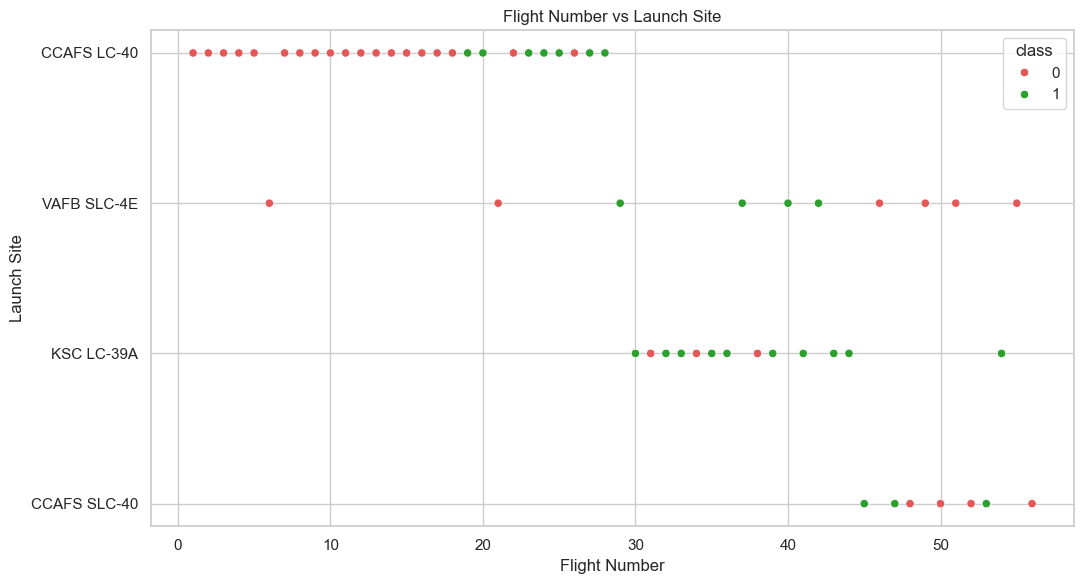

In [4]:
# 5. EDA: Flight Number vs Launch Site
if flight_col:
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.scatterplot(data=df, x=flight_col, y=site_col, hue=class_col, palette={0:"#e45756",1:"#2ca02c"}, ax=ax)
    ax.set_title("Flight Number vs Launch Site")
    ax.set_xlabel("Flight Number"); ax.set_ylabel("Launch Site")
    fig.tight_layout(); fig.savefig(OUT/"01_flight_number_vs_launch_site.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Coluna de número do voo não encontrada; gráfico ignorado.")

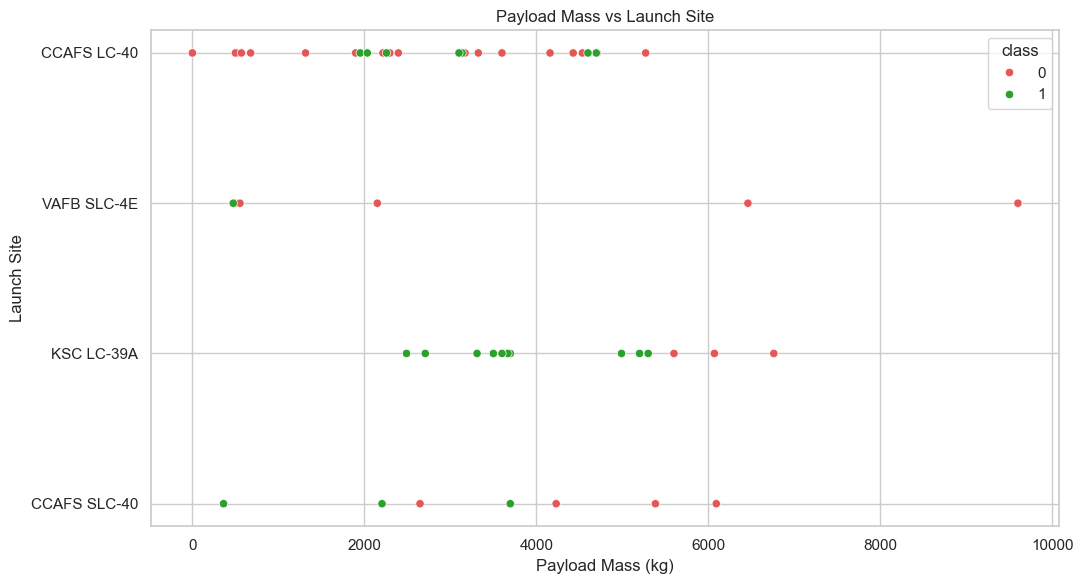

In [5]:
# 6. EDA: Payload vs Launch Site
fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=df, x=payload_col, y=site_col, hue=class_col, palette={0:"#e45756",1:"#2ca02c"}, ax=ax)
ax.set_title("Payload Mass vs Launch Site"); ax.set_xlabel("Payload Mass (kg)"); ax.set_ylabel("Launch Site")
fig.tight_layout(); fig.savefig(OUT/"02_payload_vs_launch_site.png", dpi=180, bbox_inches="tight")
plt.show()

In [6]:
# 7. EDA: taxa média de sucesso por órbita
if orbit_col:
    rates = df.groupby(orbit_col, dropna=False)[class_col].mean().sort_values()
    fig, ax = plt.subplots(figsize=(11, 6))
    rates.plot(kind="bar", ax=ax, color="#168aad")
    ax.set_title("Launch Success Rate by Orbit"); ax.set_xlabel("Orbit"); ax.set_ylabel("Success rate")
    ax.set_ylim(0, 1); plt.xticks(rotation=45, ha="right")
    fig.tight_layout(); fig.savefig(OUT/"03_success_rate_by_orbit.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Coluna Orbit não encontrada; gráfico ignorado.")

Coluna Orbit não encontrada; gráfico ignorado.


In [7]:
# 8. EDA: Flight Number vs Orbit
if flight_col and orbit_col:
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.scatterplot(data=df, x=flight_col, y=orbit_col, hue=class_col, palette={0:"#e45756",1:"#2ca02c"}, ax=ax)
    ax.set_title("Flight Number vs Orbit"); ax.set_xlabel("Flight Number"); ax.set_ylabel("Orbit")
    fig.tight_layout(); fig.savefig(OUT/"04_flight_number_vs_orbit.png", dpi=180, bbox_inches="tight")
    plt.show()

In [8]:
# 9. EDA: Payload vs Orbit
if orbit_col:
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.scatterplot(data=df, x=payload_col, y=orbit_col, hue=class_col, palette={0:"#e45756",1:"#2ca02c"}, ax=ax)
    ax.set_title("Payload Mass vs Orbit"); ax.set_xlabel("Payload Mass (kg)"); ax.set_ylabel("Orbit")
    fig.tight_layout(); fig.savefig(OUT/"05_payload_vs_orbit.png", dpi=180, bbox_inches="tight")
    plt.show()

In [9]:
# 10. EDA: tendência anual da taxa de sucesso
if date_col:
    yearly = df.dropna(subset=[date_col]).assign(Year=lambda d: d[date_col].dt.year).groupby("Year")[class_col].mean()
    fig, ax = plt.subplots(figsize=(11, 6))
    yearly.plot(marker="o", ax=ax, color="#168aad")
    ax.set_title("Yearly Launch Success Rate"); ax.set_xlabel("Year"); ax.set_ylabel("Success rate")
    ax.set_ylim(0, 1); ax.grid(True, alpha=.3)
    fig.tight_layout(); fig.savefig(OUT/"06_yearly_success_rate.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("O CSV não contém Date; o gráfico anual será omitido.")

O CSV não contém Date; o gráfico anual será omitido.


In [22]:
# 11. Folium: mapa global com locais de lançamento
# Coordenadas aproximadas dos quatro locais usados no laboratório SpaceX.
launch_sites = {
    "CCAFS LC-40": (28.5619, -80.5774),
    "KSC LC-39A": (28.6082, -80.6041),
    "VAFB SLC-4E": (34.632, -120.611),
    "CCAFS SLC-4": (28.5632, -80.5769)
}
m_sites = folium.Map(location=[25, -95], zoom_start=3, tiles="OpenStreetMap")
cluster = MarkerCluster(name="Launch sites").add_to(m_sites)
for name, (lat, lon) in launch_sites.items():
    folium.Marker([lat, lon], tooltip=name, popup=f"<b>{name}</b>").add_to(cluster)
folium.LayerControl().add_to(m_sites)
m_sites.save(str(OUT/"07_folium_launch_sites.html"))
display(m_sites)
print("Salvo:", OUT/"07_folium_launch_sites.html")

Salvo: spacex_evidence\07_folium_launch_sites.html


In [20]:
# 12. Folium: mapa com resultados por local de lançamento
# Os pontos de resultado são agregados por site, porque o CSV do dashboard não traz coordenadas por lançamento.
site_summary = df.groupby(site_col)[class_col].agg(["count","sum","mean"]).reset_index()
m_outcomes = folium.Map(location=[28.5, -95], zoom_start=3, tiles="OpenStreetMap")
for _, row in site_summary.iterrows():
    site_name = str(row[site_col])
    match = next((k for k in launch_sites if k.lower() in site_name.lower() or site_name.lower() in k.lower()), None)
    if match is None:
        # Match common site-code forms
        if "KSC" in site_name: match = "KSC LC-39A"
        elif "VAFB" in site_name or "SLC-4E" in site_name: match = "VAFB SLC-4E"
        elif "CCAFS" in site_name or "LC-40" in site_name: match = "CCAFS LC-40"
    if match is None: 
        continue
    lat, lon = launch_sites[match]
    rate = float(row["mean"]) if pd.notna(row["mean"]) else 0
    color = "green" if rate >= .7 else ("orange" if rate >= .5 else "red")
    popup = f"<b>{site_name}</b><br>Launches: {int(row['count'])}<br>Successes: {int(row['sum'])}<br>Success rate: {rate:.1%}"
    folium.CircleMarker([lat,lon], radius=10, color=color, fill=True, fill_opacity=.75, popup=popup, tooltip=f"{site_name}: {rate:.1%} success").add_to(m_outcomes)
m_outcomes.save(str(OUT/"08_folium_outcomes_by_site.html"))
display(m_outcomes)
print("Salvo:", OUT/"08_folium_outcomes_by_site.html")

Salvo: spacex_evidence\08_folium_outcomes_by_site.html


In [23]:
# 13. Folium: proximidade do local selecionado
# Círculos indicam distâncias ilustrativas; não substituem dados GIS de estradas/ferrovias.
selected = "KSC LC-39A"
lat, lon = launch_sites[selected]
m_near = folium.Map(location=[lat, lon], zoom_start=11, tiles="OpenStreetMap")
folium.Marker([lat,lon], tooltip=selected, popup=selected, icon=folium.Icon(color="blue", icon="rocket", prefix="fa")).add_to(m_near)
for radius_m, color in [(5000,"green"),(10000,"orange"),(20000,"red")]:
    folium.Circle([lat,lon], radius=radius_m, color=color, fill=False, tooltip=f"Radius: {radius_m/1000:.0f} km").add_to(m_near)
folium.LayerControl().add_to(m_near)
m_near.save(str(OUT/"09_folium_site_proximity.html"))
display(m_near)
print("Salvo:", OUT/"09_folium_site_proximity.html")
print("Importante: os círculos são buffers de distância, não estradas/ferrovias identificadas.")

Salvo: spacex_evidence\09_folium_site_proximity.html
Importante: os círculos são buffers de distância, não estradas/ferrovias identificadas.


In [13]:
# 14. Gráficos estilo dashboard: pizza por local e dispersão por payload
# Estes gráficos estáticos são evidências rápidas; o dashboard interativo é gerado na célula seguinte.
site_counts = df.groupby(site_col)[class_col].sum().sort_values(ascending=False)
fig = px.pie(values=site_counts.values, names=site_counts.index, title="Successful Launches by Site")
fig.write_image(str(OUT/"10_dashboard_successful_launches_pie.png")) if False else fig.write_html(str(OUT/"10_dashboard_successful_launches_pie.html"))
fig.show()

fig = px.scatter(df, x=payload_col, y=class_col, color=booster_col if booster_col else site_col,
                 hover_data=[site_col], title="Payload Mass vs Mission Outcome",
                 labels={payload_col:"Payload Mass (kg)", class_col:"Mission outcome"})
fig.write_html(str(OUT/"11_dashboard_payload_outcome_scatter.html"))
fig.show()
print("Gráficos interativos salvos como HTML em", OUT.resolve())

Gráficos interativos salvos como HTML em C:\Users\Marcos\Desktop\spacex_evidence


In [14]:
# 15. Criar o app Plotly Dash para capturas de tela reais
# Salva um script spacex_dashboard_app.py; execute-o no terminal e capture a tela no navegador.
app_code = r'''
from pathlib import Path
import pandas as pd
from dash import Dash, dcc, html, Input, Output
import plotly.express as px

CSV = Path(__file__).parent / "spacex_launch_dash.csv"
df = pd.read_csv(CSV)
site_col = "Launch Site"
payload_col = "Payload Mass (kg)"
class_col = "class"
booster_col = "Booster Version Category" if "Booster Version Category" in df.columns else None

app = Dash(__name__)
sites = sorted(df[site_col].dropna().unique())
options = [{"label":"All Sites","value":"ALL"}] + [{"label":s,"value":s} for s in sites]
payload_min = int(df[payload_col].min() // 1000 * 1000)
payload_max = int((df[payload_col].max() // 1000 + 1) * 1000)

app.layout = html.Div([
    html.H1("SpaceX Launch Records Dashboard", style={"textAlign":"center"}),
    html.Label("Launch Site"),
    dcc.Dropdown(id="site-dropdown", options=options, value="ALL", clearable=False),
    dcc.Graph(id="success-pie-chart"),
    html.Label("Payload range (kg)"),
    dcc.RangeSlider(id="payload-slider", min=payload_min, max=payload_max, step=1000,
                    value=[payload_min,payload_max], marks={v:str(v) for v in range(payload_min,payload_max+1, max(1000,(payload_max-payload_min)//5 or 1000))}),
    dcc.Graph(id="success-payload-scatter-chart")
], style={"fontFamily":"Arial","margin":"2rem"})

@app.callback(Output("success-pie-chart","figure"), Input("site-dropdown","value"))
def update_pie(site):
    data = df if site == "ALL" else df[df[site_col] == site]
    if site == "ALL":
        summary = data.groupby(site_col)[class_col].sum().reset_index()
        return px.pie(summary, values=class_col, names=site_col, title="Successful Launches by Site")
    counts = data[class_col].value_counts().reindex([0,1], fill_value=0).rename_axis("Outcome").reset_index(name="Count")
    counts["Outcome"] = counts["Outcome"].map({0:"Failure",1:"Success"})
    return px.pie(counts, values="Count", names="Outcome", title=f"Outcomes at {site}")

@app.callback(Output("success-payload-scatter-chart","figure"),
              Input("site-dropdown","value"), Input("payload-slider","value"))
def update_scatter(site, payload_range):
    data = df[df[payload_col].between(payload_range[0],payload_range[1])]
    if site != "ALL":
        data = data[data[site_col] == site]
    color = booster_col if booster_col else site_col
    return px.scatter(data, x=payload_col, y=class_col, color=color, hover_data=[site_col],
                      title="Payload Mass vs Mission Outcome",
                      labels={payload_col:"Payload Mass (kg)",class_col:"Mission outcome"})

if __name__ == "__main__":
    app.run(debug=False, host="127.0.0.1", port=8050)
'''
app_path = OUT/"spacex_dashboard_app.py"
app_path.write_text(app_code, encoding="utf-8")
print("App salvo:", app_path.resolve())
print("Para executar: abra um terminal na pasta spacex_evidence e rode: python spacex_dashboard_app.py")
print("Depois abra http://127.0.0.1:8050 e capture screenshots do dashboard.")

App salvo: C:\Users\Marcos\Desktop\spacex_evidence\spacex_dashboard_app.py
Para executar: abra um terminal na pasta spacex_evidence e rode: python spacex_dashboard_app.py
Depois abra http://127.0.0.1:8050 e capture screenshots do dashboard.


## Arquivos gerados

Ao executar o notebook, a pasta `spacex_evidence/` deverá conter:
- `01_...png` a `06_...png`: gráficos EDA;
- `07_...html` a `09_...html`: mapas Folium interativos;
- `10_...html` e `11_...html`: gráficos interativos de apoio;
- `spacex_dashboard_app.py`: aplicativo Dash para capturas de tela do dashboard.

**Limitação importante:** o mapa de proximidade nesta versão usa círculos de distância ao redor de um local; não identifica automaticamente ferrovias, rodovias ou costa. Para afirmar distâncias a essas feições, é necessário consultar uma fonte geográfica apropriada e calcular distâncias reais.